# Kigali Wetland Persistent-Change Monitor
**David Birenzi — BSc Software Engineering capstone**

Machine-learning monitoring of persistent change in Kigali wetlands from multi-temporal Sentinel-2 imagery.

**Research idea.** Two-date change detection fires on seasonality and temporary states. This notebook learns each wetland pixel's *normal seasonal behaviour*, tracks the deviation (residual) from that normal, and reports a change only when the deviation **persists across consecutive clear observations** — with an onset date, change type, area in hectares and confidence.

**Study wetlands** (contrasting cases): Nyandungu (restoration), Gikondo (industrial degradation → rehabilitation), Rwampara (urban/agricultural degradation → rehabilitation). Land outside each boundary inside the study window is the control ring.

Run the data pipeline first if cubes are missing: `python -m src.download --all` (internet, resumable). Everything below then runs offline.

In [1]:
import json, sys
sys.path.append('..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from src.config import WETLANDS
pd.set_option('display.max_columns', 20)
print('Sites:', {k: v['label'] for k, v in WETLANDS.items()})

Sites: {'nyandungu': 'Nyandungu Wetland', 'gikondo': 'Gikondo Wetland', 'rwampara': 'Rwampara Wetland'}


## 1 · Data
Sentinel-2 L2A, one best scene per quarter (2017–2026), SCL cloud/shadow masking, six indices at 10 m: NDVI, NDWI, MNDWI, NDMI, SAVI, BSI. Scene catalogues are stored per site so the work is reproducible from scene IDs.

In [2]:
from src.config import site_paths
for site in WETLANDS:
    cat = site_paths(site)['catalog']
    if cat.exists():
        df = pd.read_csv(cat)
        print(site, len(df), 'scenes', df.date.min(), '->', df.date.max())
    else:
        print(site, 'NO CUBE YET - run: python -m src.download --site', site)

nyandungu 38 scenes 2017-02-07 -> 2026-06-30
gikondo 37 scenes 2017-06-27 -> 2026-06-30
rwampara 37 scenes 2017-06-27 -> 2026-06-30


## 2 · Models
Two normal-behaviour models are fitted per wetland on its normal period and compared:
- **Harmonic regression** per pixel (seasonal sin/cos terms) — transparent, per-pixel level+seasonality.
- **MLP regressor** (64–32 ReLU, Adam, early stopping): seasonal harmonics + the pixel's normal NDVI/NDWI/MNDWI → expected NDVI.

The **persistence engine** flags a pixel when |observed − expected NDVI| ≥ threshold for *k* consecutive clear monitoring observations (threshold and *k* tuned on tuning blocks only). Changes are typed from NDVI/MNDWI/NDMI/BSI shifts. The **baseline** is conventional two-date NDVI differencing.

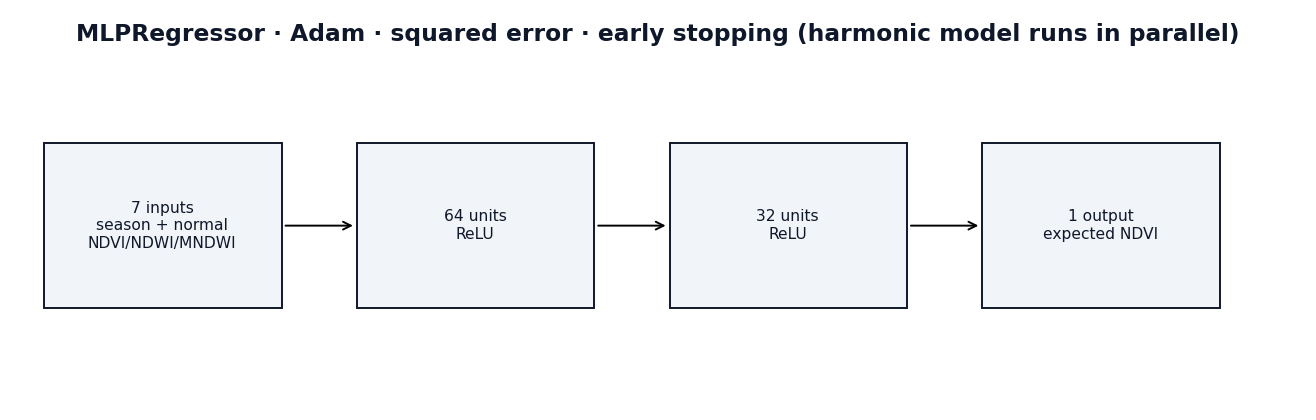

In [3]:
# Architecture of the MLP (one of the two normal-behaviour models)
display(Image('../outputs/figures/nyandungu/architecture.png'))

## 3 · Run the full analysis (all wetlands)
Trains both models per site, tunes the persistence rule, evaluates on spatially held-out blocks, builds change polygons/alerts, figures and metrics.

In [4]:
from src.analysis import run_all
all_metrics = run_all()

C:\Users\HP ENVY\OneDrive\Desktop\Mission-Capstone-Project\notebooks\..\src\analysis.py:543: RuntimeWarning: All-NaN slice encountered
  med = {k: np.nanmedian(flat[k][:, train_mask], axis=1) for k in INDICES}


C:\Users\HP ENVY\OneDrive\Desktop\Mission-Capstone-Project\notebooks\..\src\analysis.py:544: RuntimeWarning: All-NaN slice encountered
  med_monitor_ndvi = np.nanmedian(flat["ndvi"][:, monitor_mask], axis=1)


C:\Users\HP ENVY\OneDrive\Desktop\Mission-Capstone-Project\notebooks\..\src\analysis.py:145: RuntimeWarning: All-NaN slice encountered
  new_level = np.nanmedian(adj, axis=1)


C:\Users\HP ENVY\OneDrive\Desktop\Mission-Capstone-Project\notebooks\..\src\analysis.py:581: RuntimeWarning: All-NaN slice encountered
  d = {kk: (np.nanmedian(flat[kk][:, monitor_mask], axis=1) - med[kk]) for kk in ["ndvi", "mndwi", "ndmi", "bsi"]}


{
  "site": "nyandungu",
  "chosen": "MLP + persistence",
  "model_f1": 0.6655927835051546,
  "baseline_f1": 0.5917327293318233,
  "area_inside_ha": 51.47,
  "polygons": 38
}


...

C:\Users\HP ENVY\OneDrive\Desktop\Mission-Capstone-Project\notebooks\..\src\analysis.py:543: RuntimeWarning: All-NaN slice encountered
  med = {k: np.nanmedian(flat[k][:, train_mask], axis=1) for k in INDICES}


C:\Users\HP ENVY\OneDrive\Desktop\Mission-Capstone-Project\notebooks\..\src\analysis.py:544: RuntimeWarning: All-NaN slice encountered
  med_monitor_ndvi = np.nanmedian(flat["ndvi"][:, monitor_mask], axis=1)


C:\Users\HP ENVY\OneDrive\Desktop\Mission-Capstone-Project\notebooks\..\src\analysis.py:145: RuntimeWarning: All-NaN slice encountered
  new_level = np.nanmedian(adj, axis=1)


C:\Users\HP ENVY\OneDrive\Desktop\Mission-Capstone-Project\notebooks\..\src\analysis.py:581: RuntimeWarning: All-NaN slice encountered
  d = {kk: (np.nanmedian(flat[kk][:, monitor_mask], axis=1) - med[kk]) for kk in ["ndvi", "mndwi", "ndmi", "bsi"]}


{
  "site": "rwampara",
  "chosen": "Harmonic + persistence",
  "model_f1": 0.5980761187787537,
  "baseline_f1": 0.22808378588052755,
  "area_inside_ha": 56.55,
  "polygons": 62
}


## 4 · Results — model vs baseline (held-out spatial blocks)

In [5]:
rows = []
for site, m in all_metrics.items():
    for name, s in m['models'].items():
        rows.append({'site': site, 'method': name, **{k: round(s[k], 3) for k in ['precision','recall','f1','accuracy','iou']}})
pd.DataFrame(rows)

,site,method,precision,recall,f1,accuracy,iou
0,nyandungu,Harmonic + persistence,0.549,0.839,0.664,0.955,0.496
1,nyandungu,MLP + persistence,0.558,0.824,0.666,0.956,0.499
2,nyandungu,Two-date baseline,0.459,0.833,0.592,0.939,0.420
3,gikondo,Harmonic + persistence,0.801,0.967,0.876,0.979,0.779
4,gikondo,MLP + persistence,0.575,0.929,0.710,0.943,0.551
5,gikondo,Two-date baseline,0.596,0.654,0.623,0.941,0.453
6,rwampara,Harmonic + persistence,0.454,0.877,0.598,0.974,0.427
7,rwampara,MLP + persistence,0.396,0.708,0.508,0.970,0.341
8,rwampara,Two-date baseline,0.144,0.541,0.228,0.919,0.129


In [6]:
for site, m in all_metrics.items():
    print(f"{m['label']}: chosen={m['chosen_model']} | detected inside={m['area_hectares']['detected_inside_aoi']} ha of {m['aoi_hectares']} ha | control-ring={m['area_hectares']['detected_control_ring']} ha | alerts={m['n_change_polygons']}")
    print('   by type:', m['change_by_type_inside_aoi'])

Nyandungu Wetland: chosen=MLP + persistence | detected inside=51.47 ha of 127.54 ha | control-ring=877.1 ha | alerts=38
   by type: {'Built-up / bare encroachment': 0.97, 'Mixed / other persistent change': 9.36, 'Vegetation & water gain (recovery)': 7.4, 'Vegetation gain': 28.78, 'Vegetation loss': 2.55, 'Water gain': 1.8, 'Water loss (drying)': 0.61}
Gikondo Wetland: chosen=Harmonic + persistence | detected inside=81.66 ha of 104.93 ha | control-ring=541.04 ha | alerts=12
   by type: {'Built-up / bare encroachment': 1.72, 'Mixed / other persistent change': 11.3, 'Vegetation & water gain (recovery)': 6.13, 'Vegetation gain': 42.47, 'Vegetation loss': 1.34, 'Water gain': 0.32, 'Water loss (drying)': 18.38}
Rwampara Wetland: chosen=Harmonic + persistence | detected inside=56.55 ha of 134.7 ha | control-ring=563.49 ha | alerts=62
   by type: {'Built-up / bare encroachment': 18.16, 'Mixed / other persistent change': 21.93, 'Vegetation & water gain (recovery)': 0.03, 'Vegetation & water los

## 5 · Maps and time series

nyandungu


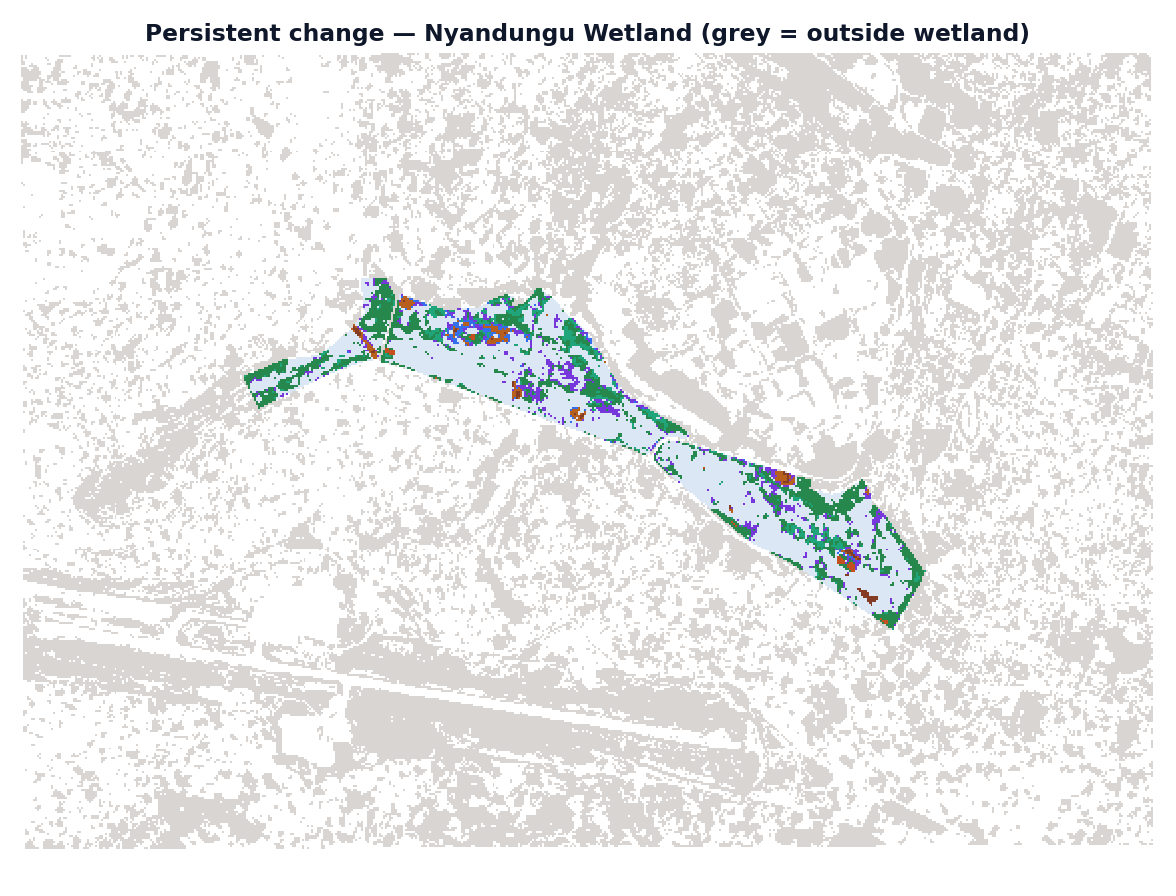

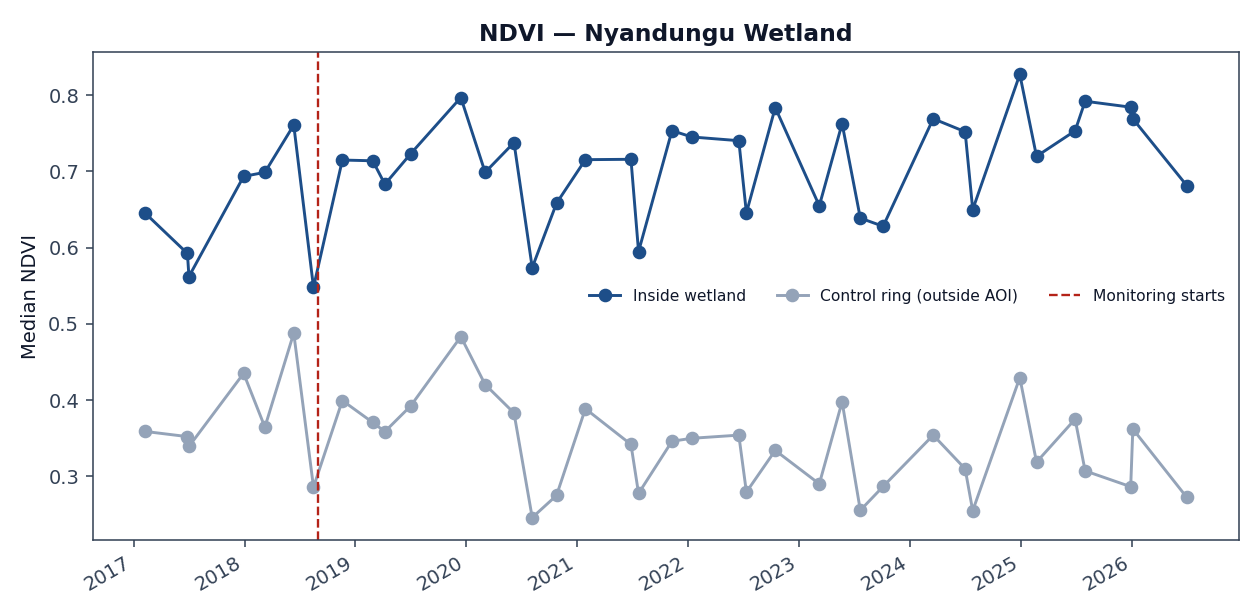

gikondo


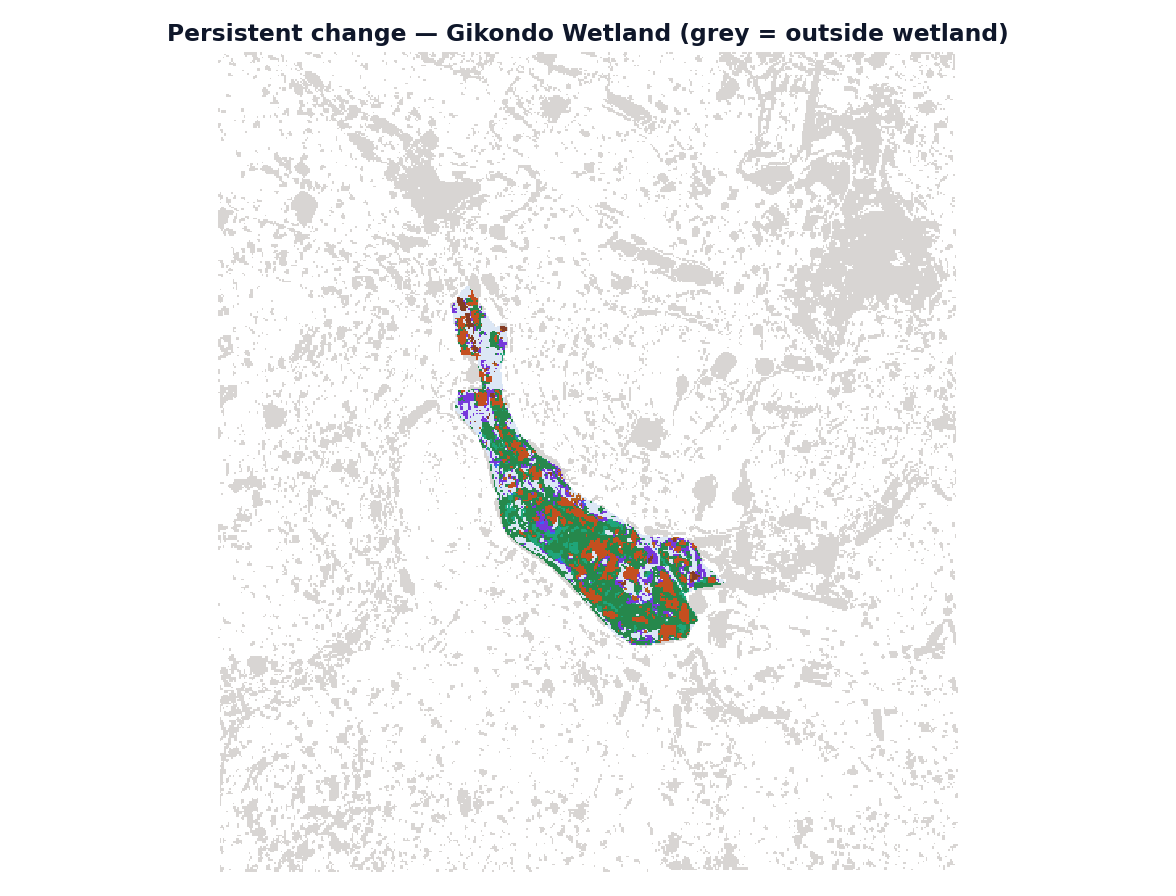

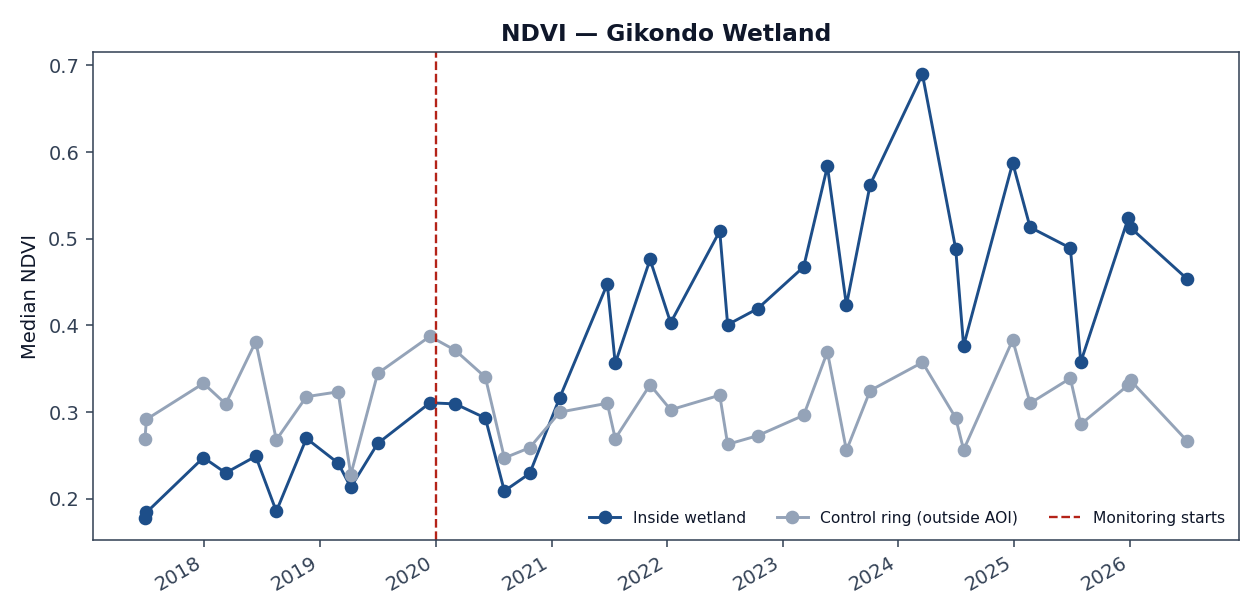

rwampara


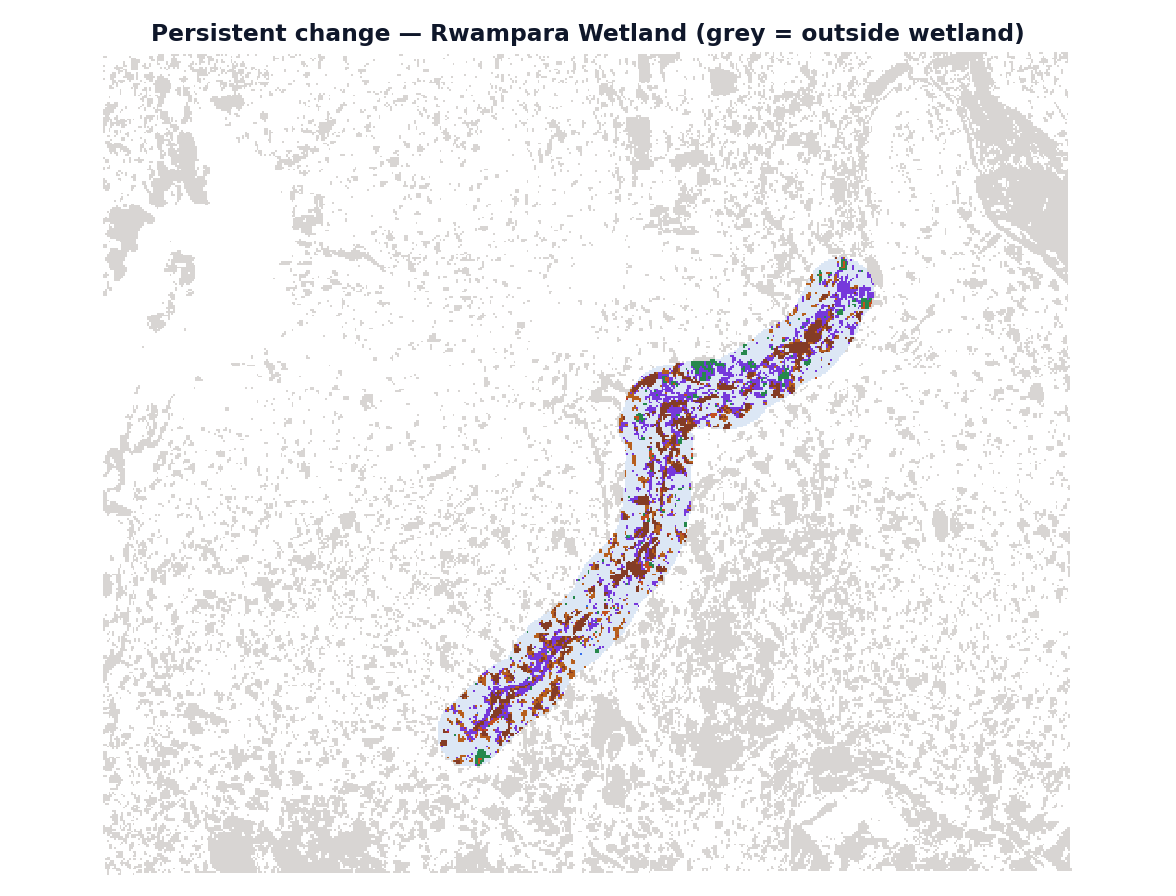

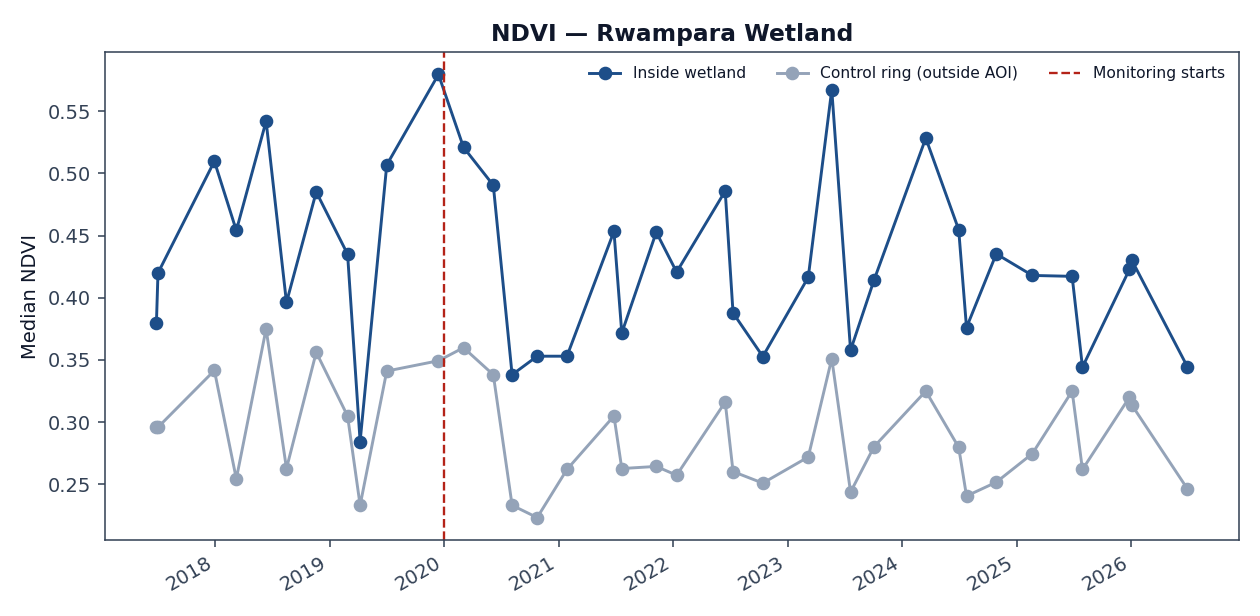

In [7]:
for site in all_metrics:
    print(site)
    display(Image(f'../outputs/figures/{site}/change_map.png'))
    display(Image(f'../outputs/figures/{site}/ndvi_timeseries.png'))

## 6 · Discussion (write-up prompts)
Answer these in the dissertation from the tables/maps above:
1. Does the proposed (persistent) model beat the two-date baseline on F1/IoU at every site? Where is precision lost, and does the map suggest those are real changes outside the reference definition?
2. Do onset years line up with the known histories (Nyandungu works 2018–2022; Gikondo/Rwampara rehabilitation from 2024)?
3. Does the control ring stay comparatively quiet, i.e. is the signal wetland-specific?
4. Which change types dominate each wetland, and does that match its story?
5. Limitations: silver-standard reference, quarterly onset precision, Rwampara delineated AOI, <0.1 ha changes invisible — see `docs/METHODS.md`. Field verification (`data/field/`) is the gold-standard next step.

In [8]:
# Alerts register preview (all sites)
import glob
rows=[]
for f in glob.glob('../outputs/changes_*.geojson'):
    d=json.load(open(f))
    rows += [x['properties'] for x in d['features']]
pd.DataFrame(rows).sort_values('area_ha', ascending=False).head(15)

,id,site,change_type,area_ha,pixels,onset_date,mean_magnitude,max_run,confidence,confidence_level,centroid_lon,centroid_lat
0,1,gikondo,Vegetation gain,73.38,7338,2022-06-16,0.2829,26,0.909,High,30.082654,-1.963298
50,1,rwampara,Mixed / other persistent change,12.19,1219,2022-10-14,0.1738,26,0.817,High,30.062980,-1.972381
51,2,rwampara,Mixed / other persistent change,10.06,1006,2022-07-11,0.1885,26,0.830,High,30.068857,-1.969183
12,1,nyandungu,Vegetation gain,9.57,957,2023-10-04,0.1993,28,0.772,High,30.143383,-1.952178
52,3,rwampara,Mixed / other persistent change,8.83,883,2024-10-28,0.2329,26,0.898,High,30.055206,-1.985826
13,2,nyandungu,Vegetation gain,6.69,669,2024-12-27,0.1922,25,0.800,High,30.158256,-1.959982
14,3,nyandungu,Vegetation gain,6.38,638,2024-03-17,0.1983,22,0.789,High,30.147766,-1.955109
53,4,rwampara,Built-up / bare encroachment,4.79,479,2022-06-16,0.1674,16,0.769,High,30.061039,-1.978981
15,4,nyandungu,Vegetation gain,4.42,442,2023-07-21,0.1938,20,0.826,High,30.138777,-1.952174
1,2,gikondo,Water loss (drying),4.06,406,2021-11-08,0.2968,23,0.914,High,30.075908,-1.951230
